In [2]:
import gymnasium as gym

# Initialise the environment
env = gym.make("LunarLander-v3", render_mode="human")

# Reset the environment to generate the first observation
observation, info = env.reset(seed=42)
for _ in range(1000):
    # this is where you would insert your policy
    action = env.action_space.sample()

    # step (transition) through the environment with the action
    # receiving the next observation, reward and if the episode has terminated or truncated
    observation, reward, terminated, truncated, info = env.step(action)

    # If the episode has ended then we can reset to start a new episode
    if terminated or truncated:
        observation, info = env.reset()

env.close()

## Maze Debugging

In [7]:
from pyamaze import maze
import pandas as pd
import tkinter as tk
import matplotlib.pyplot as plt

In [ ]:

tk.Tk.state = lambda self, s=None: self.wm_state('normal' if s == 'zoomed' else s)
def generate_df_maze(rows=20, cols=20, lp=80):
    # Create a Pyamaze maze
    m = maze(rows, cols)
    m.CreateMaze(loopPercent=lp)  # No loops to match a grid-like maze

    # List to store cell data
    maze_data = []
    for y in range(1, rows + 1):
        for x in range(1, cols + 1):
            cell = (x, y)
            cell_walls = m.maze_map[cell]  # Get wall info for each cell

            E = 1 if cell_walls['E'] else 0
            W = 1 if cell_walls['W'] else 0
            N = 1 if cell_walls['N'] else 0
            S = 1 if cell_walls['S'] else 0

            maze_data.append([f"({x},{y})", E, W, N, S])

    df = pd.DataFrame(maze_data, columns=["  cell  ", "E", "W", "N", "S"])
    if '  cell  ' in df.columns:
        df[['row', 'col']] = (
            df['  cell  '].astype(str)
            .str.replace(r'[()]', '', regex=True)
            .str.split(',', expand=True)
            .astype(int)
        )
    return df, m

In [3]:
# df_maze, m = generate_df_maze(
#             5,
#             5,
#             40
#         )
df_maze = pd.read_csv("data/rl_maze.csv")

In [14]:
m.run()

In [37]:
df_maze.iloc[44]

  cell      (5,5)
E               1
W               0
N               1
S               1
row             5
col             5
Name: 44, dtype: object

In [4]:
import networkx as nx
def _build_graph(df_maze):
        G = nx.Graph()
        for _, row in df_maze.iterrows():
            r, c = int(row['row']), int(row['col'])
            G.add_node((r, c))
            if row['E'] == 1:
                G.add_edge((r, c), (r, c+1))
            if row['W'] == 1:
                G.add_edge((r, c), (r, c - 1))
            if row['N'] == 1:
                G.add_edge((r, c), (r - 1, c))
            if row['S'] == 1:
                G.add_edge((r, c), (r + 1,c))
        return G

In [5]:
G = _build_graph(df_maze)

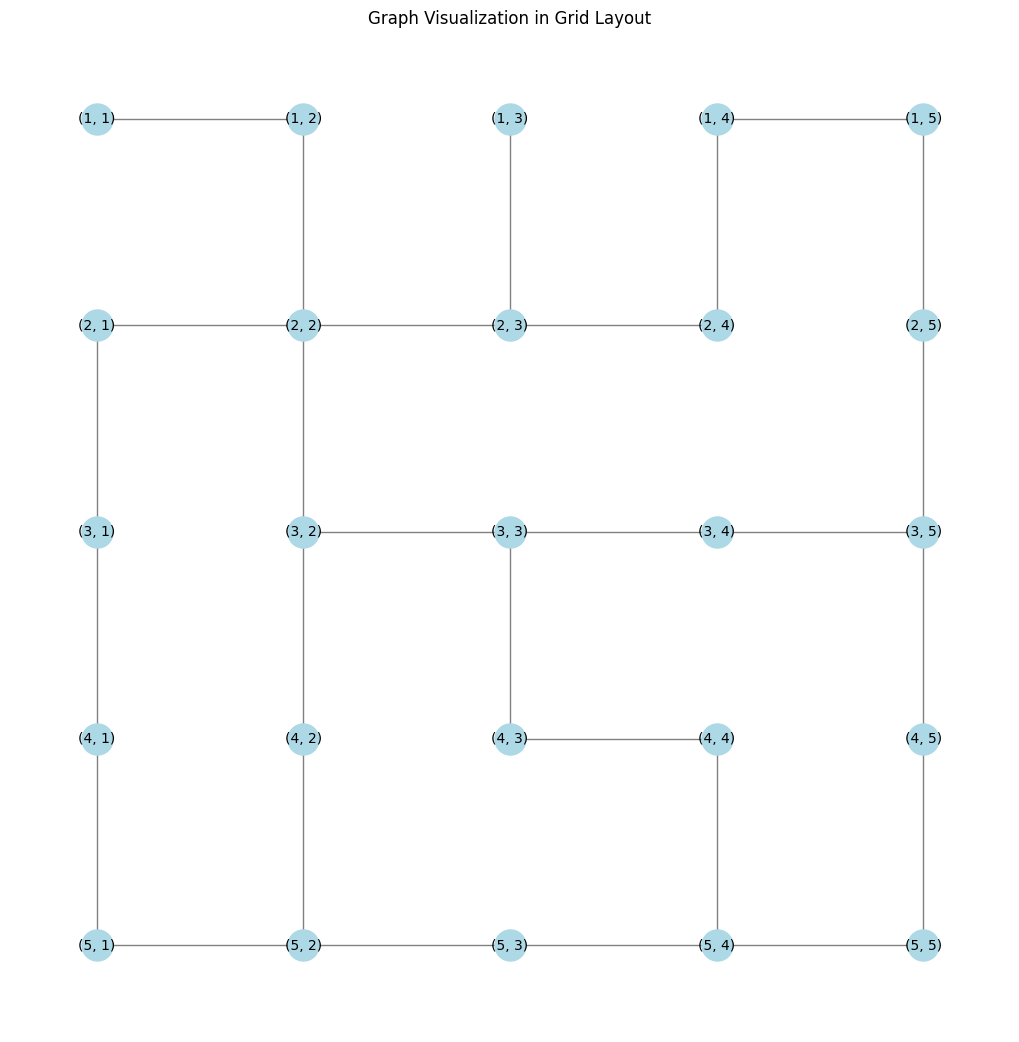

In [8]:
# Arrange nodes in a grid layout
pos = {(row['col'], row['row']): (row['row'], -row['col']) for _, row in df_maze.iterrows()}

# Draw the graph
plt.figure(figsize=(10, 10))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color='gray')
plt.title("Graph Visualization in Grid Layout")
plt.show()

In [34]:
# Print the edges of the center node
max_row = df_maze['row'].max()
max_col = df_maze['col'].max()
center_row = max_row // 2
center_col = max_col // 2
center_node = (center_col, center_row)
edges = G.edges(center_node)
print(f"Edges of the center node {center_node}: {list(edges)}")

Edges of the center node (np.int64(5), np.int64(5)): [((np.int64(5), np.int64(5)), (4, 5)), ((np.int64(5), np.int64(5)), (5, 6)), ((np.int64(5), np.int64(5)), (6, 5))]


In [18]:
df_maze.to_csv("data/rl_maze.csv", index=False)

## Plotting the Training Log

Single Agent Working

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_results = pd.read_csv("runs/sarsa/5fb6beb8/train_log.txt")

df_results.head()

,Episode,Total Reward,Epsilon
0,1,-41800.0,0.199
1,2,-40220.0,0.198
2,3,-40850.0,0.197
3,4,-40700.0,0.196
4,5,-39960.0,0.195


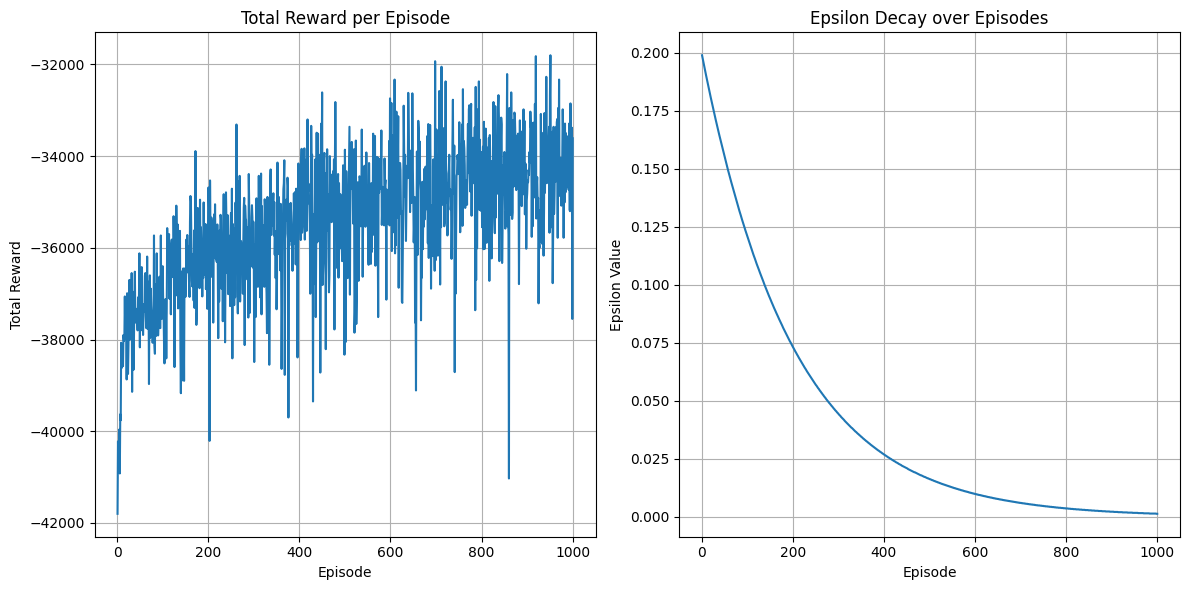

In [2]:
plt.figure(figsize=(12, 6))

# Plot 1: Total Reward over episodes
plt.subplot(1, 2, 1)
plt.plot(df_results['Episode'], df_results[' Total Reward'])
plt.title('Total Reward per Episode')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True)

# Plot 2: Epsilon over episodes
plt.subplot(1, 2, 2)
plt.plot(df_results['Episode'], df_results[' Epsilon'])
plt.title('Epsilon Decay over Episodes')
plt.xlabel('Episode')
plt.ylabel('Epsilon Value')
plt.grid(True)

plt.tight_layout()
plt.show()

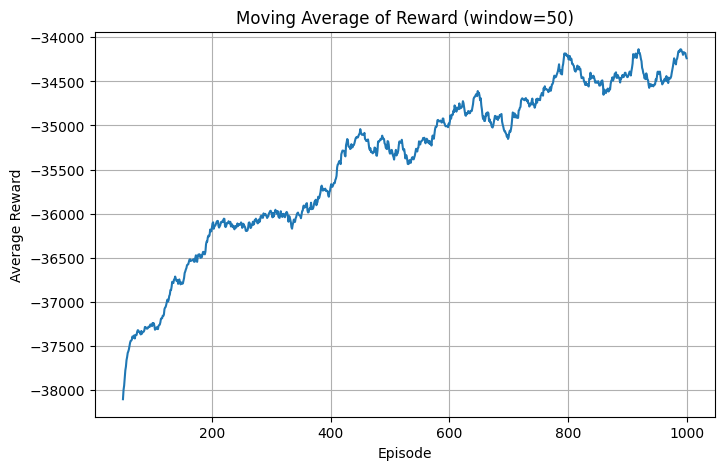

In [3]:
window_size = 50  # Adjust this for smoother or more responsive averaging
moving_avg = df_results[' Total Reward'].rolling(window=window_size).mean()

plt.figure(figsize=(8, 5))
plt.plot(df_results['Episode'][window_size-1:], moving_avg[window_size-1:])
plt.title(f'Moving Average of Reward (window={window_size})')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.grid(True)
plt.show()

## Visualizing Policy

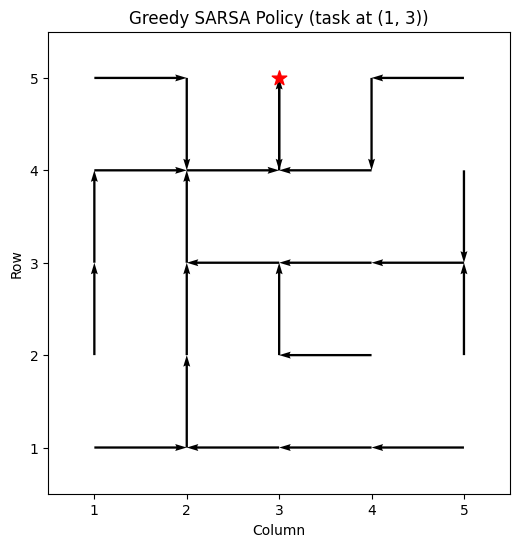

In [11]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/sarsa/train/c6f70031/policy.pkl'         # path to your pickled Q dict
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)                  # Q: dict[state] -> np.array of action‑values

# --- 2) VISUALIZATION PARAMETERS -------------
task = (1, 3)                            # fixed task location
n_rows, n_cols = 5, 5                  # dimensions of your grid
action_map = {
    0: (-1,  0),   # up
    1: ( 0,  1),   # right
    2: ( 1,  0),   # down
    3: ( 0, -1),   # left
    # extend for any extra actions you have
}

# --- 3) BUILD VECTOR FIELD + COLOR CODES ----
X, Y, U, V, colors = [], [], [], [], []
for i in range(1,n_rows+1):
    for j in range(1,n_cols+1):
        state = ((i, j), task)
        if state in Q:
            qvals = Q[state]
            col = 'black'           # seen in training
        else:
            qvals = np.zeros(len(action_map))
            col = 'red'             # never visited during training

        best_action = int(np.argmax(qvals))
        dx, dy = action_map[best_action]

        # quiver uses (x, y) = (col, row), flipping row so (0,0) is bottom‑left
        X.append(j)
        Y.append(n_rows - i+1)   # flip row so (0,0) is at bottom‑left
        U.append(dy)
        V.append(-dx)
        colors.append(col)

# --- 4) PLOT WITH QUIVER -----------------------
plt.figure(figsize=(6,6))
plt.quiver(
    X, Y, U, V,
    angles='xy', scale_units='xy', scale=1,
    width=0.005, color=colors
)

# mark the task
tx, ty = task
plt.scatter([ty], [n_rows + 1 - tx], color='red', s=120, marker='*', label='Task')

# add legend for visited vs. unseen
visited_patch = mpatches.Patch(color='black', label='Visited in training')
unseen_patch  = mpatches.Patch(color='red',   label='Unseen state')
# plt.legend(handles=[visited_patch, unseen_patch], loc='upper right')

plt.xlim(0.5, n_cols + 0.5)
plt.ylim(0.5, n_rows + 0.5)
plt.gca().set_aspect('equal')
plt.title(f"Greedy SARSA Policy (task at {task})")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()


In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/dc7dde26/policy.pkl'
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)  

In [2]:
Q

{(0,
  (0,
   0,
   0,
   0)): array([43.17174744, 11.66218507, 13.87518469, 12.47939052, 33.50948537]),
 (3,
  (0,
   0,
   0,
   0)): array([ 8.7424757 , 15.53471408, 11.04168073, 43.81166008, 35.14242441]),
 (1,
  (0,
   0,
   0,
   0)): array([ 7.68264283, 43.20282353, 12.11852941, 13.17038117, 29.03698188]),
 (2,
  (0,
   0,
   0,
   0)): array([15.86462279, 12.51771245, 43.95987774, 11.38042294, 33.93101094]),
 (4,
  (0,
   0,
   0,
   0)): array([24.87723429,  0.        ,  3.29708375,  2.28900483,  4.5       ])}

In [ ]:
state = ((1, 0, 2, 1),
  1,
  (1,
   3,
   3,
   1,
   2))
Q

{((1, 0, 2, 1),
  1,
  (1,
   3,
   3,
   1,
   2)): array([144.4232333 ,  74.71507351,  76.00220413,  72.72682029]),
 ((0, 2, 2, 1),
  2,
  (0,
   2,
   2,
   5,
   1)): array([109.43924619, 164.103034  , 111.36810171, 102.32052992]),
 ((0, 2, 2, 2),
  8,
  (1,
   1,
   1,
   5,
   0)): array([134.56479166,  42.32036628,  -0.28431195,  20.18387656]),
 ((0, 2, 2, 2),
  3,
  (5,
   5,
   5,
   5,
   5)): array([  2.77157318,  13.50857029, 106.82139772,  24.07340994]),
 ((0, 1, 0, 2),
  4,
  (4,
   4,
   5,
   5,
   5)): array([  5.49524568, 123.89515612,   7.62689688,  17.08354251]),
 ((0, 0, 2, 2),
  4,
  (5,
   3,
   5,
   5,
   4)): array([ 47.84082087,  42.90961525, 147.85820756,  44.81172558]),
 ((1, 0, 2, 1),
  4,
  (5,
   2,
   4,
   4,
   3)): array([ 36.83786691,   8.95433862, 146.28531244,  37.73997226]),
 ((2, 0, 2, 0),
  4,
  (5,
   1,
   3,
   3,
   2)): array([ 70.70451737,  55.94615565, 170.61502453,  47.64043009]),
 ((2, 0, 1, 2),
  4,
  (5,
   0,
   2,
   2,
   1)): arr

## Checking a log

In [7]:
import re

def extract_array(observation_line, key):
    # Example pattern: "'task_positions': array([4, 4, 4, 2, 2, 1]"
    pattern = rf"'{key}'\s*:\s*array\(\[([^\]]+)\]"
    match = re.search(pattern, observation_line)
    if match:
        nums_str = match.group(1)
        # Convert each number as an integer, ignoring extra spaces
        return [int(num.strip()) for num in nums_str.split(',')]
    return []

completed_tasks = 0
prev_task_positions = None

# Replace 'path/to/your/log_file.txt' with your actual log file path.
with open("tmp.txt", "r") as f:
    for line in f:
        # Process only observation lines 
        if line.startswith("Observation:"):
            task_positions = extract_array(line, "task_positions")
            ugv_positions = extract_array(line, "ugv_positions")
            print("ugv_positions", ugv_positions)
            print("task_positions", task_positions)
            
            if prev_task_positions is not None:
                for pos in ugv_positions:
                    if pos in prev_task_positions:
                        completed_tasks += 1
                        print("Task completed at position:", pos)
            # Update previous task_positions for next observation check
            prev_task_positions = task_positions

print("Total tasks completed:", completed_tasks)

ugv_positions [3, 2]
task_positions [5, 3, 5, 5, 5, 4]
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task

## Checking Occupancy Grid

In [7]:
import networkx as nx
import pandas as pd
def _build_graph(df_maze):
        G = nx.Graph()
        for _, row in df_maze.iterrows():
            r, c = int(row['row']), int(row['col'])
            G.add_node((r, c))
            if row['E'] == 1:
                G.add_edge((r, c), (r, c+1), traffic=0)
            if row['W'] == 1:
                G.add_edge((r, c), (r, c - 1), traffic=0)
            if row['N'] == 1:
                G.add_edge((r, c), (r - 1, c), traffic=0)
            if row['S'] == 1:
                G.add_edge((r, c), (r + 1,c), traffic=0)

        # directions = [(-1, 0), (0, 1), (1, 0), (0, -1)]
        # for node in G.nodes:
        #     wall_distances = []
        #     for dr, dc in directions:
        #         steps = 0
        #         current = node
        #         while steps < 1:
        #             next_node = (current[0] + dr, current[1] + dc)
        #             if not G.has_edge(current, next_node):
        #                 break
        #             steps += 1
        #             current = next_node
        #         wall_distances.append(steps)
        #     G.nodes[node]['wall_distance'] = wall_distances

        # Wall Occupancy Grid 
        max_row = df_maze['row'].max()
        max_col = df_maze['col'].max()
        kernel_size = 3
        for i in range(1,max_row+1):
            for j in range(i,max_col+1):
                occupancy_grid = [0]*kernel_size*(kernel_size+1)*2
                m = len(occupancy_grid)
                for k in range(m):
                    if k<m//2:
                        row_id = k//kernel_size
                        col_id = k%kernel_size
                        row_t_diff = row_id-2
                        row_b_diff = row_id-1
                        col_diff = col_id-1
                        cell_t = (i+row_t_diff,j+col_diff)
                        cell_b = (i+row_b_diff,j+col_diff)
                        if G.has_edge(cell_t,cell_b):
                            occupancy_grid[k] = 1
                    else:
                        k_ = k-m//2
                        row_id = k_%kernel_size
                        col_id = k_//kernel_size
                        col_l_diff = col_id-2
                        col_r_diff = col_id-1
                        row_diff = row_id-1
                        cell_l = (j+row_diff,i+col_l_diff)
                        cell_r = (j+row_diff,i+col_r_diff)
                        if G.has_edge(cell_l,cell_r):
                            occupancy_grid[k] = 1
                G.nodes[(i,j)]['occupancy_grid'] = occupancy_grid

        return G

In [8]:
df_maze = pd.read_csv("data/rl_maze.csv")
G = _build_graph(df_maze)

In [9]:
G.nodes[(2,2)]['occupancy_grid']

[0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1]

In [6]:
i,j = 2,2
kernel_size = 3
occupancy_grid = [0]*kernel_size*(kernel_size+1)*2
m = len(occupancy_grid)
for k in range(m):
    if k<m//2:
        row_id = k//kernel_size
        col_id = k%kernel_size
        row_t_diff = row_id-2
        row_b_diff = row_id-1
        col_diff = col_id-1
        cell_t = (i+row_t_diff,j+col_diff)
        cell_b = (i+row_b_diff,j+col_diff)
        if G.has_edge(cell_t,cell_b):
            occupancy_grid[k] = 1
    else:
        k_ = k-m//2
        print(k_)
        row_id = k_%kernel_size
        col_id = k_//kernel_size
        print(row_id,col_id)
        col_l_diff = col_id-2
        col_r_diff = col_id-1
        row_diff = row_id-1
        cell_l = (j+row_diff,i+col_l_diff)
        cell_r = (j+row_diff,i+col_r_diff)
        print(cell_l,cell_r)
        if G.has_edge(cell_l,cell_r):
            occupancy_grid[k] = 1
G.nodes[(i,j)]['occupancy_grid'] = occupancy_grid

0
0 0
(1, 0) (1, 1)
1
1 0
(2, 0) (2, 1)
2
2 0
(3, 0) (3, 1)
3
0 1
(1, 1) (1, 2)
4
1 1
(2, 1) (2, 2)
5
2 1
(3, 1) (3, 2)
6
0 2
(1, 2) (1, 3)
7
1 2
(2, 2) (2, 3)
8
2 2
(3, 2) (3, 3)
9
0 3
(1, 3) (1, 4)
10
1 3
(2, 3) (2, 4)
11
2 3
(3, 3) (3, 4)


# Checking if a State is in a Polcy

In [1]:
import pickle
import ast

# Prompt the user for the pickle file path and state tuple
policy_path = "runs/sarsa/c00d345d/policy.pkl"
state = ((3, 1, 3, 1, 5), (0, 0, 0, 0))

# Convert the input string to a tuple safely
try:
    # state = ast.literal_eval(state_input)
    if not isinstance(state, tuple):
        raise ValueError("Input is not a tuple.")
except Exception as e:
    print("Invalid state tuple input:", e)
    raise

# Load the policy from the provided pickle file
try:
    with open(policy_path, 'rb') as f:
        policy = pickle.load(f)
except Exception as e:
    print(f"Error loading policy from {policy_path}: {e}")
    raise

# Check if the state is in the policy dictionary
if state in policy:
    print(f"State {state} is present in the policy pickle file.")
    print(f"Action values: {policy[state]}")
else:
    print(f"State {state} is NOT present in the policy pickle file.")

State ((3, 1, 3, 1, 5), (0, 0, 0, 0)) is present in the policy pickle file.
Action values: [1174.07049016  324.39017714   83.22633506  453.48865802  272.12460621]


# Checking Atari Env

In [3]:
import gymnasium as gym
env = gym.make("PongNoFrameskip-v4", render_mode="rgb_array")
env = gym.wrappers.RecordEpisodeStatistics(env)

# observation, info = env.reset(seed=42)
# done = False
# while True:
#     action = env.action_space.sample()
#     observation, reward, terminated, truncated, info = env.step(action)
#     if terminated or truncated:
#         observation, info = env.reset()
# env.close()

In [5]:
env.observation_space.shape

(210, 160, 3)

# Checking RecordStat Wrapper

In [1]:
import gymnasium as gym
import yaml

import envs

In [11]:
config = yaml.safe_load(open("runs/dijkstra/config.yaml"))
env = gym.make("LMDEnv-v0", config=config, render_mode="print")
env = gym.wrappers.RecordEpisodeStatistics(env)

In [12]:
obs, info = env.reset(seed=42)

/home/shinobi-owl/anaconda3/envs/clean_rl/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:188: UserWarning: WARN: The obs returned by the `reset()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


In [31]:
info

{'time_elapsed': 350.0,
 'current_timestep': 7,
 'num_tasks_completed': 2,
 'total_ev_distance': 350.0,
 'total_energy_consumed': 350.0,
 'avg_task_completion_time': 300.0,
 'active_tasks': [(8, 6)],
 'red_roads': [((2, 5), (3, 5)),
  ((3, 5), (3, 6)),
  ((3, 5), (4, 5)),
  ((4, 5), (5, 5)),
  ((3, 6), (3, 7)),
  ((3, 6), (4, 6)),
  ((5, 6), (4, 6)),
  ((3, 7), (2, 7)),
  ((4, 6), (4, 7)),
  ((4, 7), (5, 7))],
 'yellow_roads': [((3, 4), (3, 5)),
  ((2, 5), (2, 6)),
  ((4, 4), (4, 5)),
  ((1, 6), (2, 6)),
  ((5, 5), (5, 6)),
  ((3, 7), (3, 8)),
  ((4, 7), (4, 8))],
 'episode': {'r': array([45.], dtype=float32),
  'l': array([6], dtype=int32),
  't': array([117.31592], dtype=float32)}}

In [28]:
obs

array([101, 101,   0,   2,   1,   0,   0,   0,   0], dtype=int32)

In [30]:
obs, reward, terminated, truncated, info = env.step(2)

In [10]:
env.close()

# Plotting Trajectories for ICRA

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pygame
import os
import math

# Define colors for pygame
WHITE = (255, 255, 255)
BLACK = (0, 0, 0)
RED = (255, 0, 0)
GREEN = (0, 255, 0)
BLUE = (0, 0, 255)
YELLOW = (255, 255, 0)
GRAY = (200, 200, 200)
DARK_GREEN = (0, 100, 0)
CYAN = (0, 255, 255)
MAGENTA = (255, 0, 255)
ORANGE = (255, 165, 0)
PURPLE = (128, 0, 128)

In [56]:
G = nx.read_gml('data/maze.gml')
G_converted = nx.Graph()
for u, v, data in G.edges(data=True):
    u_converted = eval(u) if isinstance(u, str) else u
    v_converted = eval(v) if isinstance(v, str) else v
    G_converted.add_edge(u_converted, v_converted, **data)
G = G_converted

yellow_roads = []
red_roads = []
for u, v, data in G.edges(data=True):
    if 'traffic' in data:
        if data['traffic'] == 1:
            red_roads.append((u, v))
        elif data['traffic'] == 2:
            yellow_roads.append((u, v))

G.edges[(3, 7), (2, 7)]['traffic'] = 2
G.edges[(3, 6), (3, 7)]['traffic'] = 2

In [64]:
# Calculate screen dimensions based on maze size and cell pixel size
# Add padding for potential info text display later
padding = 100
cell_size_px = 100
max_row, max_col = 7, 7
wall_thickness = 6
warehouse_pos = (max_row//2+1, max_col//2+1)
active_task = (2,6)
time_elapsed = 500
current_timestep = 10
total_ev_distance = 0

ugv_list = []
ugv_list.append({
    'ugv_pos': (1,7),
    'ugv_heading_dir': 0,
    'color': MAGENTA,
    'trajectory': [(4,4),(4,5),(3,5),(3,6),(3,7),(2,7),(1,7)],
}) #Dijkstra
ugv_list.append({
    'ugv_pos': (1,7),
    'ugv_heading_dir': 0,
    'color': PURPLE,
    'trajectory': [(4,4),(4,5),(3,5),(3,6),(3,7),(2,7),(1,7)],
}) #DynaQ
ugv_list.append({
    'ugv_pos': (2,6),
    'ugv_heading_dir': 1,
    'color': GREEN,
    'trajectory': [(4,4),(4,5),(3,5),(3,4),(3,3),(3,2),(2,2),(2,3),(2,4),(2,5),(2,6)],
}) #DQN
ugv_list.append({
    'ugv_pos': (3,7),
    'ugv_heading_dir': 0,
    'color': ORANGE,
    'trajectory': [(4,4),(4,5),(3,5),(3,6),(3,7)],
}) #SARSA

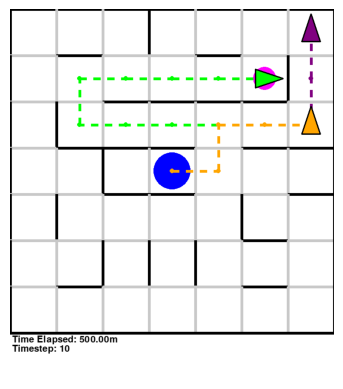

In [65]:
pygame.init()
pygame.display.set_caption("LMD Simulation")
pygame.display.set_mode((1, 1), pygame.NOFRAME)  # Create a minimal display to enable image loading
clock = pygame.time.Clock()

screen_width = max_col * cell_size_px
screen_height = max_row * cell_size_px + padding # Add padding at the bottom

# Load font
try:
    font = pygame.font.SysFont(None, 30) # Adjust font size as needed
except Exception as e:
    print(f"Warning: Could not load system font. Text rendering might fail. Error: {e}")
    font = pygame.font.Font(None, 30) # Fallback to default font

truck_img_path = os.path.join('data/truck.png')

def _cell_to_pygame(row, col):
        """Converts maze (row, col) to pygame pixel coordinates (top-left of cell)."""
        # Pygame origin (0,0) is top-left
        px = (col - 1) * cell_size_px
        py = (row - 1) * cell_size_px # Adjusted for top-left origin
        return int(px), int(py)

def _cell_to_pygame_center(row, col):
        """Converts maze (row, col) to pygame pixel coordinates (center of cell)."""
        px, py = _cell_to_pygame(row, col)
        px += cell_size_px // 2
        py += cell_size_px // 2
        return int(px), int(py)

surface = pygame.Surface((screen_width, screen_height))
render_surface = surface

truck_image = pygame.image.load(truck_img_path).convert_alpha() # Use convert_alpha for transparency
scale_factor = 0.8
img_size = int(cell_size_px * scale_factor)
truck_image = pygame.transform.scale(truck_image, (img_size, img_size))

# --- Drawing ---
render_surface.fill(WHITE) # Clear surface

# --- Draw Maze Area (Grid and Walls) ---
maze_area_height = max_row * cell_size_px
# --- Draw Maze Area (Grid and Walls) using self.G ---
for r in range(1, max_row + 1):
    for c in range(1, max_col + 1):
        current_node = (r, c)
        # Skip if node somehow doesn't exist in the graph (should not happen for grid)
        if current_node not in G:
            continue

        px_top_left, py_top_left = _cell_to_pygame(r, c)

        # Check North Wall: Draw wall if no edge exists between current node and North neighbor (r-1, c)
        # G.has_edge handles boundary cases (e.g., r=1, neighbor (0,c) doesn't exist, so has_edge is False)
        north_neighbor = (r - 1, c)
        if not G.has_edge(current_node, north_neighbor):
            # Draw the North wall of cell (r, c)
            pygame.draw.line(render_surface, BLACK, (px_top_left, py_top_left), (px_top_left + cell_size_px, py_top_left), wall_thickness)
        else:
            pygame.draw.line(render_surface, GRAY, (px_top_left, py_top_left), (px_top_left + cell_size_px, py_top_left), wall_thickness)

        # Check West Wall: Draw wall if no edge exists between current node and West neighbor (r, c-1)
        west_neighbor = (r, c - 1)
        if not G.has_edge(current_node, west_neighbor):
            # Draw the West wall of cell (r, c)
            pygame.draw.line(render_surface, BLACK, (px_top_left, py_top_left), (px_top_left, py_top_left + cell_size_px), wall_thickness)
        else:
            pygame.draw.line(render_surface, GRAY, (px_top_left, py_top_left), (px_top_left, py_top_left + cell_size_px), wall_thickness)

# Draw outer boundary walls (South and East edges explicitly)
# This ensures the bottom border of the last row and the right border of the last column are drawn.
pygame.draw.line(render_surface, BLACK, (0, maze_area_height), (screen_width, maze_area_height), wall_thickness) # Bottom boundary
pygame.draw.line(render_surface, BLACK, (screen_width, 0), (screen_width, maze_area_height), wall_thickness) # Right boundary


# # --- Draw Traffic Roads ---
# road_thickness = max(1, int(cell_size_px * 0.15)) # Adjust thickness relative to cell size
# for u, v in red_roads:
#     u_px_c, u_py_c = _cell_to_pygame_center(u[0], u[1])
#     v_px_c, v_py_c = _cell_to_pygame_center(v[0], v[1])
#     pygame.draw.line(render_surface, RED, (u_px_c, u_py_c), (v_px_c, v_py_c), road_thickness)
# for u, v in yellow_roads:
#     u_px_c, u_py_c = _cell_to_pygame_center(u[0], u[1])
#     v_px_c, v_py_c = _cell_to_pygame_center(v[0], v[1])
#     pygame.draw.line(render_surface, YELLOW, (u_px_c, u_py_c), (v_px_c, v_py_c), road_thickness)


# --- Draw Warehouse ---
wh_r, wh_c = warehouse_pos
wh_px_c, wh_py_c = _cell_to_pygame_center(wh_r, wh_c)
warehouse_radius = int(cell_size_px * 0.4)
pygame.draw.circle(render_surface, BLUE, (wh_px_c, wh_py_c), warehouse_radius)

# --- Draw Tasks ---
task_r, task_c = active_task
task_px_c, task_py_c = _cell_to_pygame_center(task_r, task_c)
task_radius = int(cell_size_px * 0.25)
pygame.draw.circle(render_surface, MAGENTA, (task_px_c, task_py_c), task_radius)

for ugv in ugv_list:
    ugv_pos = ugv['ugv_pos']
    ugv_heading_dir = ugv['ugv_heading_dir']
    ugv_color = ugv['color']
    ugv_r, ugv_c = ugv_pos
    ugv_px_c, ugv_py_c = _cell_to_pygame_center(ugv_r, ugv_c)
    # Draw UGV as a triangle arrow pointing towards heading
    size = img_size  # use same visual scale as the truck image
    length = size * 0.5
    back_dist = length * 0.5
    base_half = size * 0.25

    # Map heading -> angle degrees: 1: up (-90), 2: right (0), 3: down (90), 4: left (180)
    angle_deg = (ugv_heading_dir-1) * 90
    theta = math.radians(angle_deg)

    cx, cy = ugv_px_c, ugv_py_c
    tip = (cx + math.cos(theta) * length, cy + math.sin(theta) * length)
    base_center = (cx - math.cos(theta) * back_dist, cy - math.sin(theta) * back_dist)
    perp = theta + math.pi / 2
    left = (base_center[0] + math.cos(perp) * base_half, base_center[1] + math.sin(perp) * base_half)
    right = (base_center[0] - math.cos(perp) * base_half, base_center[1] - math.sin(perp) * base_half)

    points = [(int(tip[0]), int(tip[1])), (int(left[0]), int(left[1])), (int(right[0]), int(right[1]))]

    pygame.draw.polygon(render_surface, ugv_color, points)  # filled arrow
    pygame.draw.polygon(render_surface, BLACK, points, max(1, int(wall_thickness/2)))  # outline

    ugv_trajectory = ugv.get('trajectory', [])
    # Draw trajectory as dotted line
    if len(ugv_trajectory) > 1:
        trajectory_points = [_cell_to_pygame_center(r, c) for r, c in ugv_trajectory]
        
        # Draw dotted line with appropriate color
        for i in range(len(trajectory_points) - 1):
            # Use pygame.draw.line with optional width and tuple of (length of dash, length of gap)
            # Draw dashed line between trajectory_points[i] and trajectory_points[i+1]
            start = trajectory_points[i]
            end = trajectory_points[i + 1]
            x1, y1 = start
            x2, y2 = end
            dx, dy = x2 - x1, y2 - y1
            dist = math.hypot(dx, dy)
            if dist > 0:
                dash_len = max(5, int(cell_size_px * 0.15))  # dash length relative to cell size
                gap_len = dash_len  # equal gap
                step = dash_len + gap_len
                width = max(1, int(wall_thickness))
                t = 0.0
                while t < dist:
                    t_end = min(t + dash_len, dist)
                    sx = x1 + (dx * (t / dist))
                    sy = y1 + (dy * (t / dist))
                    ex = x1 + (dx * (t_end / dist))
                    ey = y1 + (dy * (t_end / dist))
                    pygame.draw.line(render_surface, ugv_color, (int(sx), int(sy)), (int(ex), int(ey)), width)
                    t += step
            
            # Add small circles at each trajectory point for better visibility
            point_radius = 5
            for point in trajectory_points:
                pygame.draw.circle(render_surface, ugv_color, point, point_radius)

# --- Draw Info Text ---
if font:
    info_y_start = maze_area_height + 5 # Start below maze area
    info_line_height = 20
    texts = [
        f"Time Elapsed: {time_elapsed:.2f}m",
        f"Timestep: {current_timestep}",
        # f"Total Dist: {total_ev_distance:.1f}m",
    ]
    for i, text in enumerate(texts):
        text_surface = font.render(text, True, BLACK)
        render_surface.blit(text_surface, (5, info_y_start + i * info_line_height))

img = pygame.surfarray.array3d(render_surface)
img = np.transpose(img, (1, 0, 2)) # Pygame's (width, height) to (height, width) for matplotlib
plt.imshow(img)
plt.axis('off')

pygame.display.quit()
pygame.quit()
screen = None # Mark as closed

In [66]:
plt.imsave("maze_render.png", img)

Training Plots

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# DQN
df_loss = pd.read_csv("runs/dqn/dqn_td_loss.csv")
df_rew = pd.read_csv("runs/dqn/dqn_rew.csv")

# SARSA
df_sarsa = pd.read_csv("runs/sarsa/train_log.txt")

# DynaQ
df_dyna = pd.read_csv("runs/dynaq/train_log.txt")

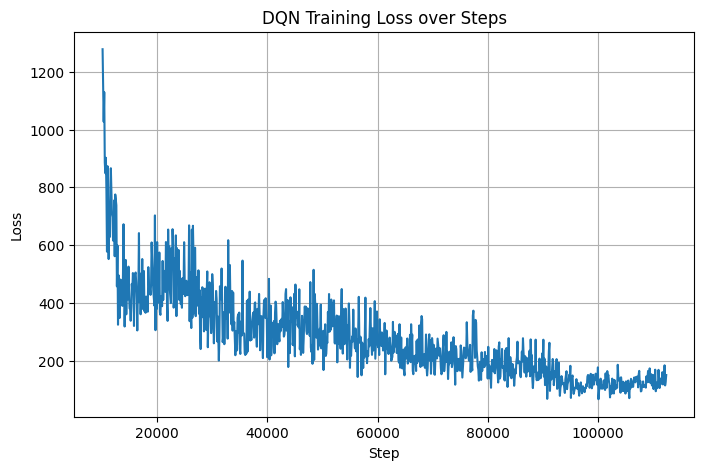

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(df_loss['Step'], df_loss['Value'])
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('DQN Training Loss over Steps')
plt.grid(True)
plt.show()

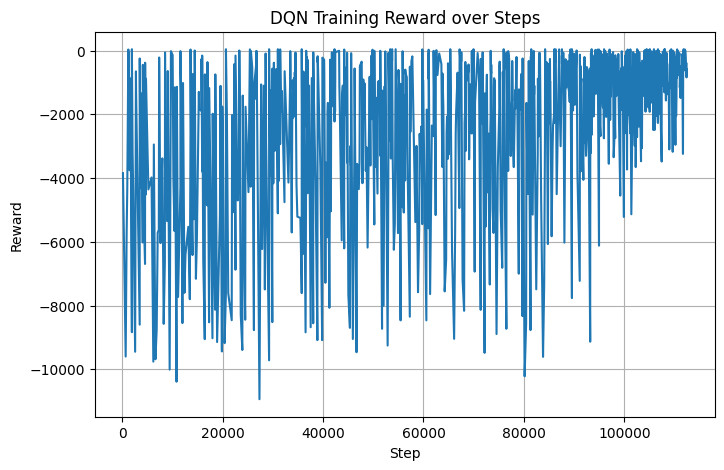

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(df_rew['Step'], df_rew['Value'])
plt.xlabel('Step')
plt.ylabel('Reward')
plt.title('DQN Training Reward over Steps')
plt.grid(True)
plt.show()

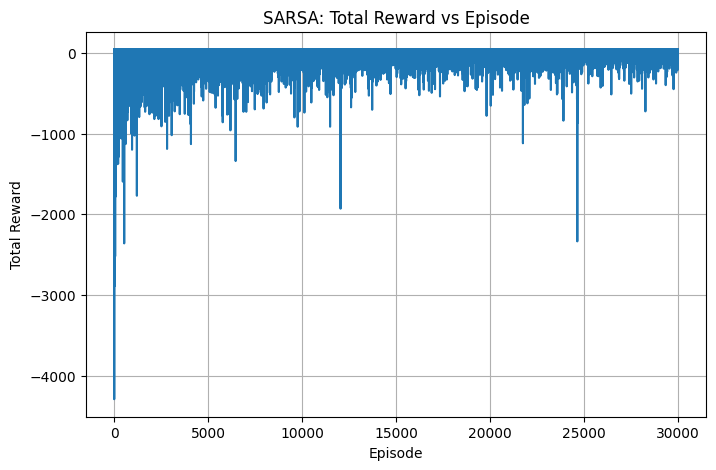

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(df_sarsa['Episode'], df_sarsa[' Total Reward'])
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('SARSA: Total Reward vs Episode')
plt.grid(True)
plt.show()

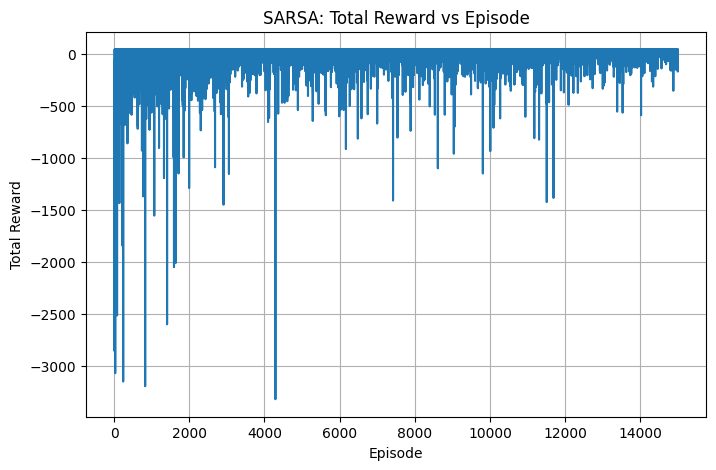

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(df_dyna['Episode'], df_dyna[' Total Reward'])
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('SARSA: Total Reward vs Episode')
plt.grid(True)
plt.show()

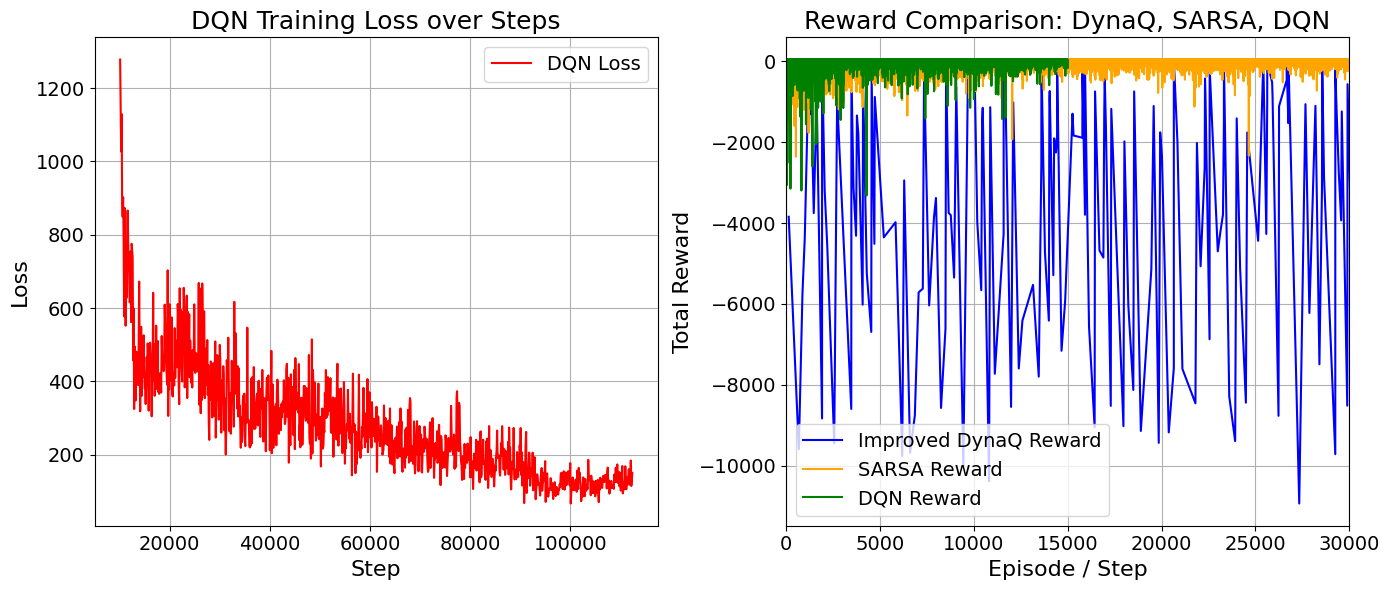

In [17]:
plt.figure(figsize=(14, 6))

# Left subplot: DQN Loss vs Step
plt.subplot(1, 2, 1)
plt.plot(df_loss['Step'], df_loss['Value'], label='DQN Loss', color='red')
plt.xlabel('Step', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.title('DQN Training Loss over Steps', fontsize=18)
plt.grid(True)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)

# Right subplot: Reward vs Episode/Step for DQN, SARSA, DynaQ
plt.subplot(1, 2, 2)
plt.plot(df_rew['Step'], df_rew['Value'], label='Improved DynaQ Reward', color='blue')
plt.plot(df_sarsa['Episode'], df_sarsa[' Total Reward'], label='SARSA Reward', color='orange')
plt.plot(df_dyna['Episode'], df_dyna[' Total Reward'], label='DQN Reward', color='green')
plt.xlabel('Episode / Step', fontsize=16)
plt.ylabel('Total Reward', fontsize=16)
plt.title('Reward Comparison: DynaQ, SARSA, DQN', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True)
plt.legend(fontsize=14)
plt.xlim(0, 30000)

plt.tight_layout()
plt.show()